In [1]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

from nlp_pipeline.nlp.similarity import word2vec, sbert, tfidf
from nlp_pipeline import config

BOOK = 11
print('corpus', len(config.BOOK_COLLECTION), 'livres')

corpus 21 livres


In [2]:
t0 = time.time()
res_w2v = word2vec.compute(BOOK, use_cache=True)
print('word2vec', f'{time.time()-t0:.1f}s', len(res_w2v))
for i, titre in enumerate(res_w2v, 1):
    print(i, titre)

word2vec 0.0s 5
1 Through the Looking-Glass
2 The murder of Roger Ackroyd
3 The Mysterious Affair at Styles
4 The Secret Garden
5 Peter Pan


In [3]:
t0 = time.time()
res_sbert = sbert.compute(BOOK, use_cache=True)
print('sbert', f'{time.time()-t0:.1f}s', len(res_sbert))
for i, titre in enumerate(res_sbert, 1):
    print(i, titre)

sbert 0.0s 5
1 The Secret Garden
2 Through the Looking-Glass
3 Poirot Investigates
4 The murder of Roger Ackroyd
5 Peter Pan


In [4]:
t0 = time.time()
res_tfidf = tfidf.compute(BOOK, use_cache=False)
print('tfidf', f'{time.time()-t0:.1f}s', len(res_tfidf))
for i, titre in enumerate(res_tfidf, 1):
    print(i, titre)

tfidf 0.6s 5
1 Through the Looking-Glass
2 The Adventures of Sherlock Holmes
3 Frankenstein; Or, The Modern Prometheus
4 The War of the Worlds
5 The Jungle Book


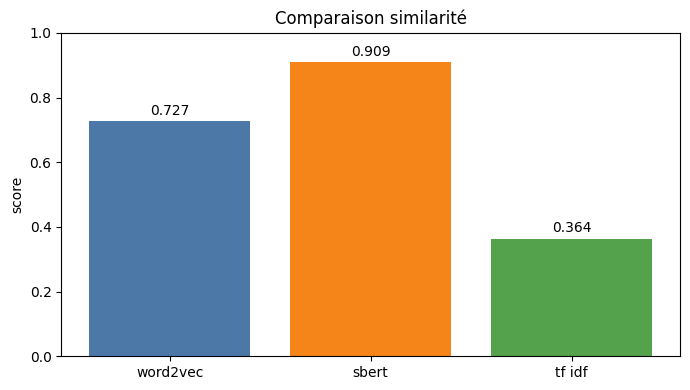

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from nlp_pipeline.nlp.similarity import eval

resultats = {'word2vec': res_w2v, 'sbert': res_sbert, 'tf idf': res_tfidf}
scores = {nom: eval.compare(res) for nom, res in resultats.items()}

noms = list(scores.keys())
x = np.arange(len(noms))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x, [scores[n]['score_equilibre'] for n in noms], color=['#4c78a8', '#f58518', '#54a24b'])
ax.set_xticks(x)
ax.set_xticklabels(noms)
ax.set_ylabel('score')
ax.set_ylim(0, 1)
ax.set_title('Comparaison similarité')
for i, n in enumerate(noms):
    ax.text(i, scores[n]['score_equilibre'] + 0.02, f"{scores[n]['score_equilibre']:.3f}", ha='center')
plt.tight_layout()
plt.show()